In [20]:
#Load Packages
#--------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd

In [44]:
#Load Data
#--------------------------------------------
communities = gpd.read_file("/home/wxp9261/ISR/Chicago_Community_areas-shp")
communities = communities.to_crs("EPSG:4326")
openair_full = pd.read_csv("/home/wxp9261/OpenAir/1YearOAC.csv")
openair_full.head()
#print(openair_full["no2Conc1HourMean.value"].mean())

15.395989240378135


In [26]:
#Annualize Openair
#--------------------------------------------
openair_annual = (
    openair_full
    .groupby("sensor_name", as_index=False)
    .mean(numeric_only=True)
)

In [27]:
#Make annualized data geospatial
#--------------------------------------------
openair_annual = gpd.GeoDataFrame(
    openair_annual,
    geometry=gpd.points_from_xy(openair_annual["longitude"], openair_annual["latitude"]),
    crs="EPSG:4326",
)

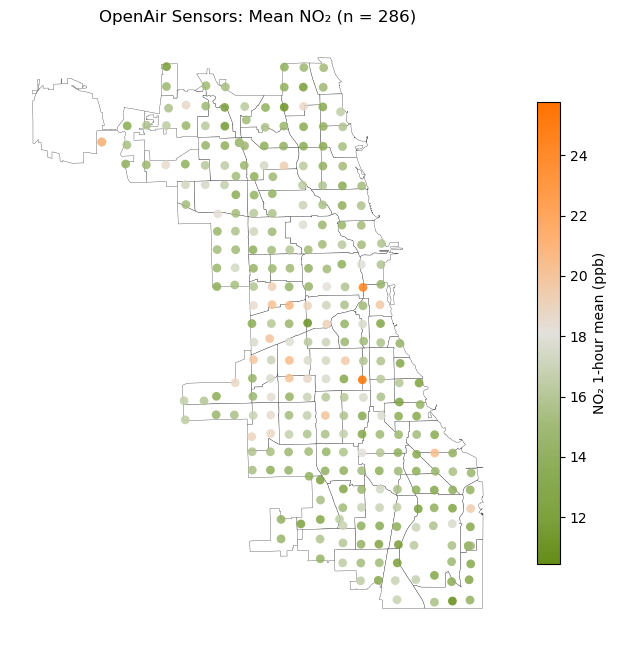

In [28]:
#Plot mean calibrated NO2 over Chicago communities 
#--------------------------------------------

#Fun color map!
from pypalettes import load_cmap
cmap = load_cmap("Avedon", cmap_type="continuous", reverse = True)

#Set figure size
fig, ax = plt.subplots(figsize=(8, 10))

#Plot community areas
communities.plot(ax=ax, color="white", edgecolor="black", linewidth=0.2)

#Plot mean annual calibrated NO2 at each sensor
openair_annual.sort_values("no2Conc1HourMean.value").plot(
    ax=ax,
    column="no2Conc1HourMean.value",
    cmap=cmap,
    markersize=40,
    alpha=0.85,
    edgecolor="black",
    linewidth=0,
    legend=True,
    legend_kwds={"label": "NO\u2082 1-hour mean (ppb)", "shrink": 0.6},
)

# Add Title
ax.set_title(f"OpenAir Sensors: Mean NO\u2082 (n = {len(openair_annual)})")

# No axis labels
ax.axis("off")

#Let's see the plot! 
plt.show()

In [6]:
#Load the location of 47th Street Rail Yard as a geodataframe
#--------------------------------------------

from shapely.geometry import Point

address = gpd.GeoDataFrame(
    {"name": ["47th St Yard"]},
    geometry=[Point(-87.6369542, 41.8053667)],
    crs="EPSG:4326"
)

/home/wxp9261/.conda/envs/env1/lib/python3.14/site-packages/pyproj/transformer.py:816: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return self._transformer._transform_point(
/home/wxp9261/.conda/envs/env1/lib/python3.14/site-packages/pyproj/transformer.py:816: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return self._transformer._transform_point(


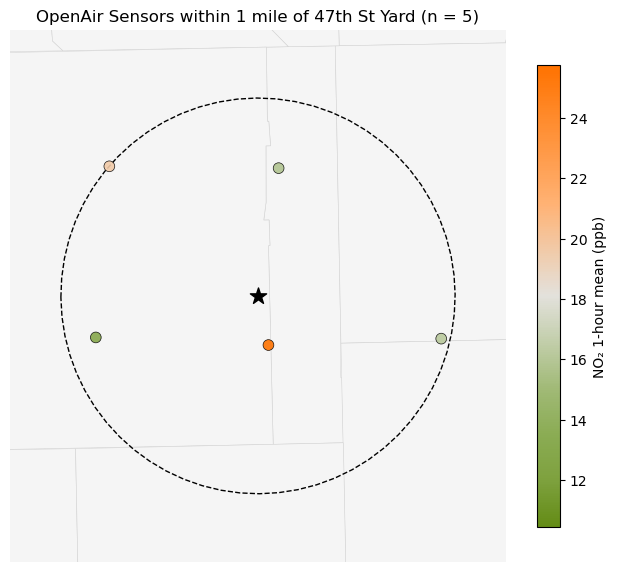

In [29]:
#Plot sensors within 1 mile of the 47th Street Rail Yard
#--------------------------------------------

#Convert mile to meters
mile = 1609.344 

#Make 1 mile buffer
buffer_poly = (
    address.to_crs(address.estimate_utm_crs())
    .buffer(mile)
    .to_crs("EPSG:4326")
    .iloc[0]
)
#Make a geodataframe for the buffer
buffer_gdf = gpd.GeoDataFrame(geometry=[buffer_poly], crs="EPSG:4326")

#Make a dataframe for the sensors within the buffer
openair_1mi = openair_annual[openair_annual.within(buffer_poly)]

#Fun color bar from pypalette
cmap = load_cmap("Avedon", cmap_type="continuous", reverse = True)  # same color scale as the full-city map

#Data column of interest (this is for brevity, col is a lot shorter)
col = "no2Conc1HourMean.value"

#Plot communities, buffer circle, and rail yard
fig, ax = plt.subplots(figsize=(8, 10))
communities_ll.plot(ax=ax, color="whitesmoke", edgecolor="lightgray", linewidth=0.4)
buffer_gdf.boundary.plot(ax=ax, color="black", linestyle="--", linewidth=1)
address.plot(ax=ax, color="black", marker="*", markersize=150, zorder=5)

#Plot mean annual NO2 for sensors within the buffer
openair_1mi.sort_values(col).plot(
    ax=ax,
    column=col,
    cmap=cmap,
    vmin=openair_annual[col].min(),  
    vmax=openair_annual[col].max(),
    markersize=60,
    alpha=0.9,
    edgecolor="black",
    linewidth=0.5,
    legend=True,
    legend_kwds={"label": "NO\u2082 1-hour mean (ppb)", "shrink": 0.6},
    zorder=4,
)

# Zoom figure to the buffer with some padding
minx, miny, maxx, maxy = buffer_gdf.total_bounds
pad = 0.005  # degrees
ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)
ax.set_aspect(1 / np.cos(np.radians((miny + maxy) / 2)))

#Title, axis, and plotting!
ax.set_title(f"OpenAir Sensors within 1 mile of {address['name'].iloc[0]} (n = {len(openair_1mi)})")
ax.axis("off")
plt.show()

/tmp/ipykernel_3087598/1739562768.py:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  diurnal[time_col] = pd.to_datetime(diurnal[time_col], utc=True).dt.tz_convert("America/Chicago")


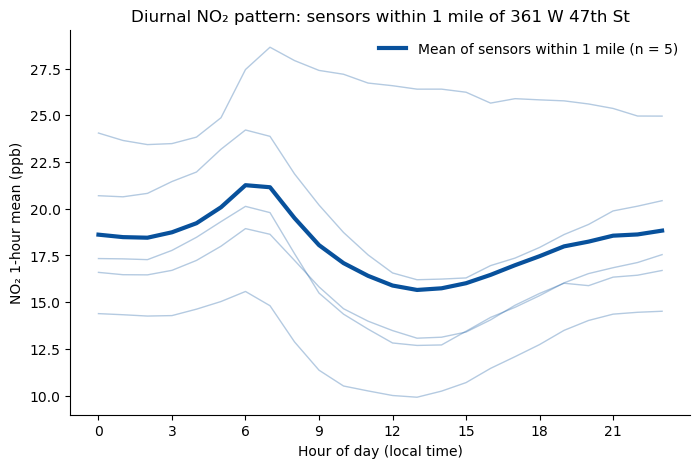

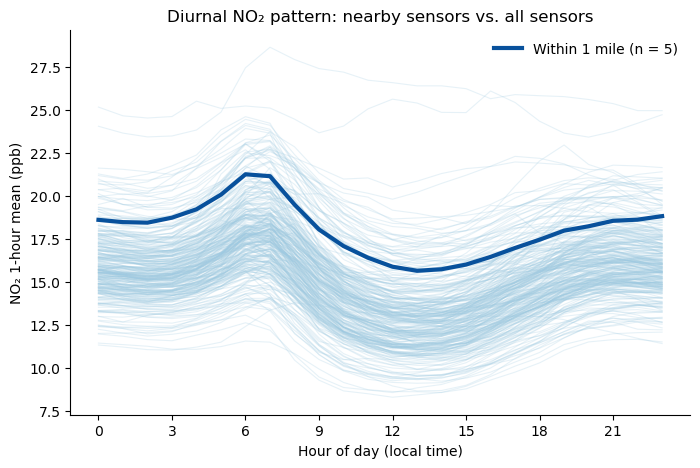

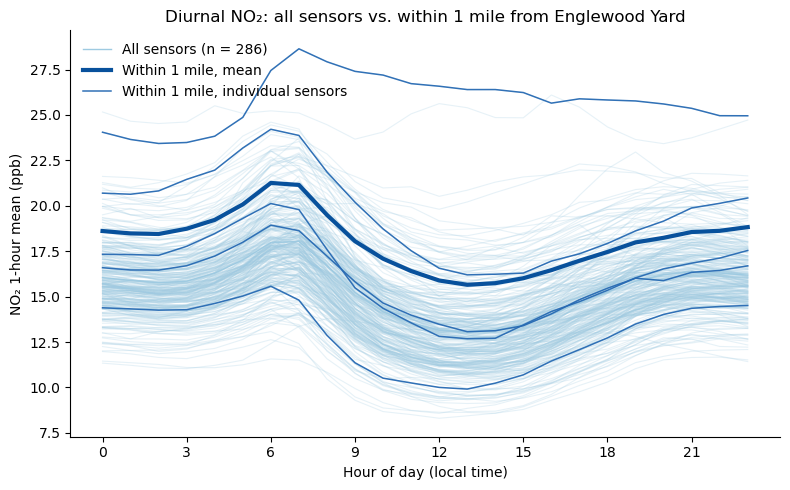

In [41]:
#Comparative Diurnal Figures!
#--------------------------------------------

#Set column(s) of interest
col = "no2Conc1HourMean.value"
time_col = "startofperiod" 

# Prep: hour of day in local (Chicago) time
diurnal = openair_full[["sensor_name", time_col, col]].copy()
diurnal[time_col] = pd.to_datetime(diurnal[time_col], utc=True).dt.tz_convert("America/Chicago")
diurnal["hour"] = diurnal[time_col].dt.hour

diurnal_all = diurnal[diurnal["sensor_name"].isin(openair_annual["sensor_name"])]
diurnal_1mi = diurnal[diurnal["sensor_name"].isin(openair_1mi["sensor_name"])]

# Function that organizes mean NO2 by hour for each sensor (rows = hour, columns = sensor)
def sensor_diurnal(d):
    return d.groupby(["hour", "sensor_name"])[col].mean().unstack("sensor_name")

#Establish plotting dataframes using sensor_diurnal function
diu_all = sensor_diurnal(diurnal_all)
diu_1mi = sensor_diurnal(diurnal_1mi)

#Set colors
muted = "#9ecae1"
dark = "#08519c"

#Set plot style so that we don't plot every hour
def style(ax):
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlabel("Hour of day (local time)")
    ax.set_ylabel("NO\u2082 1-hour mean (ppb)")
    ax.spines[["top", "right"]].set_visible(False)

# Plot 1: diurnal for sensors within 1 mile, with mean bolded
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(diu_1mi.index, diu_1mi.values, color=dark, alpha=0.3, linewidth=1)  #individual sensors
ax.plot(diu_1mi.index, diu_1mi.mean(axis=1), color=dark, linewidth=3,
        label=f"Mean of sensors within 1 mile (n = {diu_1mi.shape[1]})")   #mean 

#Title, axes, legend, and show!
ax.set_title("Diurnal NO\u2082 pattern: sensors within 1 mile of 361 W 47th St")
ax.legend(frameon=False)
style(ax)
plt.show()

# Plot 2: all sensors (muted) vs. 1-mile sensors (dark)

#Set figure
fig, ax = plt.subplots(figsize=(8, 5))

# Plot individual lines
ax.plot(diu_all.index, diu_all.values, color=muted, alpha=0.25, linewidth=0.8)

# Mean of sensors within one mile of the yard
ax.plot(diu_1mi.index, diu_1mi.mean(axis=1), color=dark, linewidth=3,
        label=f"Within 1 mile (n = {diu_1mi.shape[1]})")

#Title, axes, legend, and show!
ax.set_title("Diurnal NO\u2082 pattern: nearby sensors vs. all sensors")
ax.legend(frameon=False)
style(ax)
plt.show()

#Plot 3: all sensors (muted), 1-mile ind (medium), 1-mile mean (dark) -- this one is busy but I like it haha
#--------------------------------------------

#New medium blue hue
medium = "#276ab3"

# ---- Three-way comparison ----
fig, ax = plt.subplots(figsize=(8, 5))

# All sensors (light blue): individual lines, mean
ax.plot(diu_all.index, diu_all.values, color=muted, alpha=0.25, linewidth=0.8)
ax.plot(diu_all.index, diu_all.mean(axis=1), color=muted, linewidth=1,
        label=f"All sensors (n = {diu_all.shape[1]})", zorder=2)

# Within 1 mile (dark blue): mean
ax.plot(diu_1mi.index, diu_1mi.mean(axis=1), color=dark, linewidth=3,
        label=f"Within 1 mile, mean", zorder=3)

# Five nearest (medium blue): each sensor as its own line, no mean
for i, sensor in enumerate(diu_1mi.columns):
    ax.plot(diu_1mi.index, diu_1mi[sensor], color=medium, linewidth=1.1, alpha=0.95,
            label=f"Within 1 mile, individual sensors" if i == 0 else None,
            zorder=4)

ax.set_title("Diurnal NO\u2082: all sensors vs. within 1 mile from Englewood Yard")
ax.legend(frameon=False)
style(ax)
plt.tight_layout()
plt.show()

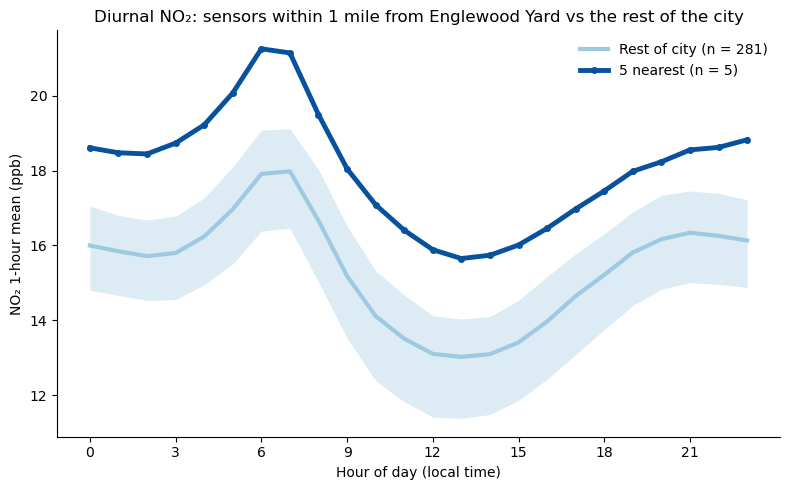

In [43]:
#More Diurnal Figures -- less busy
#--------------------------------------------

#ID which sensors are closest to the yard? 
ids_1mi   = set(diurnal_1mi["sensor_name"])
ids_rest = set(openair_annual["sensor_name"]) - ids_1mi 

#Separate in-buffer sensors from the rest
diu_rest = sensor_diurnal(df[df["sensor_name"].isin(ids_rest)])
diu_1mi    = sensor_diurnal(df[df["sensor_name"].isin(ids_1mi)])

#Set figure
fig, ax = plt.subplots(figsize=(8, 5))

# Everywhere except the buffer (light blue) -- as quartiles
ax.fill_between(diu_rest.index,
                diu_rest.quantile(0.25, axis=1),
                diu_rest.quantile(0.75, axis=1),
                color=muted, alpha=0.35, linewidth=0)
ax.plot(diu_rest.index, diu_rest.mean(axis=1), color=muted, linewidth=3,
        label=f"Rest of city (n = {diu_rest.shape[1]})", zorder=2) #mean of everywhere outside of buffer

# Mean of 1-mile
ax.plot(diu_1mi.index, diu_1mi.mean(axis=1), color=dark, linewidth=3.5,
        marker="o", markersize=4,
        label=f"5 nearest (n = {diu_1mi.shape[1]})")

ax.set_title("Diurnal NO\u2082: sensors within 1 mile from Englewood Yard vs the rest of the city")
ax.legend(frameon=False)
style(ax)
plt.tight_layout()
plt.show()